# Winger Profiles: PCA + Clustering

This notebook builds scouting profiles from `winger_features.parquet` and exports cluster insights.

In [66]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

DATA_PATH = Path("../data/processed/winger_features.parquet")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MINUTES_MIN = 300
VARIANCE_TARGET = 0.85
K_RANGE = range(2, 9)
RANDOM_STATE = 42


In [67]:
df = pd.read_parquet(DATA_PATH)
print("Raw shape:", df.shape)
print("Columns:", list(df.columns))

required_cols = {"player_id", "minutes"}
missing_required = required_cols - set(df.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {sorted(missing_required)}")

candidate_features = [
    "dribbles_per90",
    "carries_per90",
    "passes_per90",
    "shots_per90",
    "xg_per90",
    "dribbles_attempted_per90",
    "dribbles_successful_per90",
    "progressive_carries_per90",
]
feature_cols = [c for c in candidate_features if c in df.columns]

if len(feature_cols) < 3:
    raise ValueError(f"Need at least 3 per90 features. Found: {feature_cols}")

keep_cols = ["player_id", "minutes"] + (["player_name"] if "player_name" in df.columns else []) + feature_cols
df_model = df[keep_cols].copy()

if df_model["player_id"].duplicated().any():
    df_model = (
        df_model.sort_values(["player_id", "minutes"], ascending=[True, False])
        .drop_duplicates(subset=["player_id"], keep="first")
    )

df_model["minutes"] = pd.to_numeric(df_model["minutes"], errors="coerce").fillna(0)
for c in feature_cols:
    df_model[c] = pd.to_numeric(df_model[c], errors="coerce")

df_model = df_model[df_model["minutes"] >= MINUTES_MIN].dropna(subset=feature_cols).copy()

if len(df_model) < 20:
    raise ValueError(f"Not enough players after filtering: {len(df_model)}")

print("Modeling shape:", df_model.shape)
print("Using features:", feature_cols)
df_model.head()


Raw shape: (1438, 13)
Columns: ['player_id', 'dribbles', 'carries', 'passes', 'shots', 'xg', 'player_name', 'minutes', 'dribbles_per90', 'carries_per90', 'passes_per90', 'shots_per90', 'xg_per90']
Modeling shape: (1438, 8)
Using features: ['dribbles_per90', 'carries_per90', 'passes_per90', 'shots_per90', 'xg_per90']


,player_id,minutes,player_name,dribbles_per90,carries_per90,passes_per90,shots_per90,xg_per90
0,2941,1040.0,Ismaïla Sarr,2.596154,20.423077,15.317308,1.817308,0.293834
1,2944,1170.0,Benjamin Corgnet,0.615385,6.692308,10.000000,0.307692,0.027052
2,2948,780.0,Nabil Fekir,1.384615,11.653846,8.769231,0.807692,0.137362
3,2950,910.0,Jonas Martin,1.483516,34.615385,38.373626,0.989011,0.162480
4,2955,4030.0,Ronny Rodelin,1.607940,35.285360,47.724566,3.171216,0.273195


In [68]:
X = df_model[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_full = PCA(random_state=RANDOM_STATE)
_ = pca_full.fit_transform(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cum_var, VARIANCE_TARGET) + 1)
n_components = max(2, min(n_components, X_scaled.shape[1]))

pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("Chosen components:", n_components)
print("Explained variance:", pca.explained_variance_ratio_.sum())


Chosen components: 3
Explained variance: 0.9497250430529105


In [69]:
ks, sil_scores, inertias = [], [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_pca)
    ks.append(k)
    sil_scores.append(silhouette_score(X_pca, labels))
    inertias.append(km.inertia_)

model_selection = pd.DataFrame({"k": ks, "silhouette": sil_scores, "inertia": inertias})
best_k = int(model_selection.loc[model_selection["silhouette"].idxmax(), "k"])
print(model_selection)
print("Selected k:", best_k)


   k  silhouette      inertia
0  2    0.438489  3626.934890
1  3    0.344636  2772.053874
2  4    0.304619  2349.928315
3  5    0.307011  2033.503749
4  6    0.304285  1799.911740
5  7    0.290363  1638.083965
6  8    0.287847  1500.041156
Selected k: 2


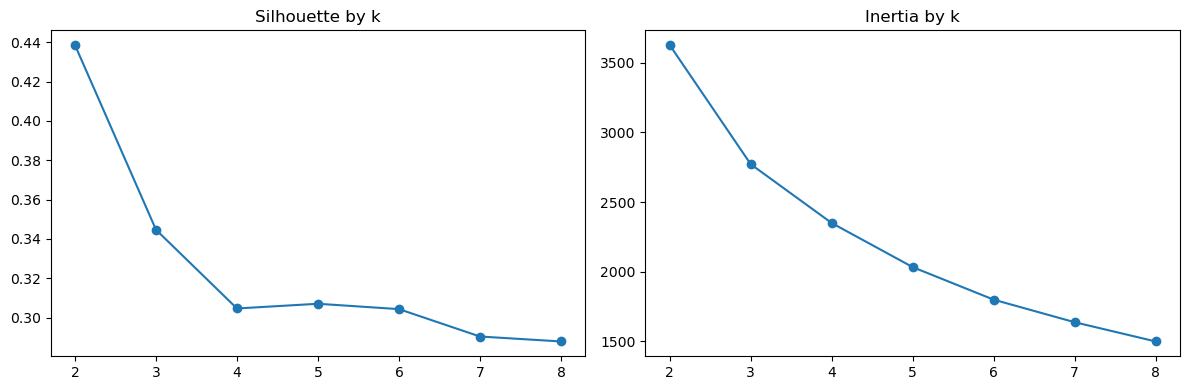

In [70]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(model_selection["k"], model_selection["silhouette"], marker="o")
ax[0].set_title("Silhouette by k")
ax[1].plot(model_selection["k"], model_selection["inertia"], marker="o")
ax[1].set_title("Inertia by k")
plt.tight_layout()


In [71]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
profiles = df_model.copy()
profiles["cluster"] = kmeans.fit_predict(X_pca)

for i in range(X_pca.shape[1]):
    profiles[f"pc{i+1}"] = X_pca[:, i]

profiles["cluster"].value_counts().sort_index()


cluster
0    504
1    934
Name: count, dtype: int64

In [72]:
cluster_summary = profiles.groupby("cluster")[feature_cols + ["minutes"]].mean().round(3)
cluster_summary_z = ((cluster_summary - cluster_summary.mean()) / cluster_summary.std(ddof=0)).round(2)

def _z(row, col):
    return float(row[col]) if col in row.index and pd.notna(row[col]) else 0.0

def infer_cluster_name(row):
    d, c, p, s, x = _z(row, "dribbles_per90"), _z(row, "carries_per90"), _z(row, "passes_per90"), _z(row, "shots_per90"), _z(row, "xg_per90")
    if d >= 0.7 and c >= 0.7 and p <= 0.4 and s <= 0.6: return "Direct Runner"
    if p >= 0.7 and d >= 0.2 and s <= 0.5: return "Playmaker Winger"
    if s >= 0.7 and x >= 0.7: return "Inside Forward Finisher"
    if d >= 0.8 and s >= 0.5: return "1v1 Attacker"
    if p >= 0.4 and c >= 0.4 and d >= 0.2: return "Balanced Creator"
    dominant = max({"dribbles_per90": d, "carries_per90": c, "passes_per90": p, "shots_per90": s, "xg_per90": x}.items(), key=lambda kv: kv[1])[0]
    return {"dribbles_per90": "1v1 Specialist", "carries_per90": "Ball Progressor", "passes_per90": "Wide Playmaker", "shots_per90": "Shot-Heavy Winger", "xg_per90": "Box Threat Winger"}[dominant]

cluster_name_map = {c: infer_cluster_name(cluster_summary_z.loc[c]) for c in cluster_summary_z.index}
profiles["cluster_name"] = profiles["cluster"].map(cluster_name_map)

cluster_summary_named = cluster_summary.reset_index()
cluster_summary_named["cluster_name"] = cluster_summary_named["cluster"].map(cluster_name_map)
cluster_summary_z_named = cluster_summary_z.reset_index()
cluster_summary_z_named["cluster_name"] = cluster_summary_z_named["cluster"].map(cluster_name_map)

display(cluster_summary_named)
display(cluster_summary_z_named)


,cluster,dribbles_per90,carries_per90,passes_per90,shots_per90,xg_per90,minutes,cluster_name
0,0,2.746,30.240,30.781,1.765,0.182,2103.988,Inside Forward Finisher
1,1,1.037,12.665,13.400,0.649,0.062,1098.597,1v1 Specialist


,cluster,dribbles_per90,carries_per90,passes_per90,shots_per90,xg_per90,minutes,cluster_name
0,0,1.0,1.0,1.0,1.0,1.0,1.0,Inside Forward Finisher
1,1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1v1 Specialist


In [73]:
centroids = kmeans.cluster_centers_
rows = []
for c in sorted(profiles["cluster"].unique()):
    idx = profiles.index[profiles["cluster"] == c].tolist()
    points = X_pca[[profiles.index.get_loc(i) for i in idx], :]
    dists = np.linalg.norm(points - centroids[c], axis=1)
    rep_idx_local = np.argsort(dists)[:10]
    rep_global_idx = [idx[j] for j in rep_idx_local]
    cols = ["player_id", "minutes", "cluster", "cluster_name"] + (["player_name"] if "player_name" in profiles.columns else [])
    block = profiles.loc[rep_global_idx, cols + feature_cols].copy()
    block["distance_to_centroid"] = dists[rep_idx_local]
    rows.append(block.sort_values("distance_to_centroid"))
representatives = pd.concat(rows, ignore_index=True)
representatives.head(20)


,player_id,minutes,cluster,cluster_name,player_name,dribbles_per90,carries_per90,passes_per90,shots_per90,xg_per90,distance_to_centroid
0,24740,4030.0,0,Inside Forward Finisher,Ivo Iličević,2.612903,29.947891,30.439206,1.674938,0.196221,0.138280
1,13322,780.0,0,Inside Forward Finisher,Greg Stewart,2.538462,26.423077,32.653846,1.961538,0.150936,0.204915
2,6720,4810.0,0,Inside Forward Finisher,Pablo Sarabia García,2.413721,29.918919,30.835759,1.852391,0.156337,0.248510
3,4260,2860.0,0,Inside Forward Finisher,Romain Hamouma,2.958042,27.723776,29.863636,1.699301,0.171771,0.275465
4,159764,520.0,0,Inside Forward Finisher,Jorge Ortiz Mendoza,2.769231,33.230769,29.769231,2.423077,0.123083,0.303519
5,11539,3510.0,0,Inside Forward Finisher,Adrián Embarba Blázquez,3.051282,31.076923,31.897436,1.743590,0.161660,0.315184
6,5560,3510.0,0,Inside Forward Finisher,Carlos Alberto Vela Garrido,2.743590,28.948718,27.076923,1.512821,0.197691,0.370344
7,6859,4810.0,0,Inside Forward Finisher,Nicola Sansone,2.787942,30.218295,28.646570,1.740125,0.137164,0.381627
8,15553,1560.0,0,Inside Forward Finisher,Karen Julia Carney,2.480769,28.903846,33.230769,1.442308,0.174011,0.417990
9,10598,390.0,0,Inside Forward Finisher,Jovane Eduardo Borges Cabral,3.000000,33.000000,28.615385,2.307692,0.157402,0.421157


In [74]:
scouting = profiles.copy()
for c in feature_cols:
    scouting[f"{c}_pct"] = scouting[c].rank(pct=True) * 100

scouting_cols = ["player_id"] + (["player_name"] if "player_name" in scouting.columns else []) + ["cluster", "cluster_name", "minutes"] + feature_cols + [f"{c}_pct" for c in feature_cols]
scouting = scouting[scouting_cols].sort_values(["cluster", "minutes"], ascending=[True, False])
scouting.head(20)


,player_id,player_name,cluster,cluster_name,minutes,dribbles_per90,carries_per90,passes_per90,shots_per90,xg_per90,dribbles_per90_pct,carries_per90_pct,passes_per90_pct,shots_per90_pct,xg_per90_pct
303,5503,Lionel Andrés Messi Cuccittini,0,Inside Forward Finisher,22880.0,5.192308,47.934441,45.452360,3.666084,0.470774,97.913769,99.026426,97.844228,98.817803,98.400556
214,4320,Neymar da Silva Santos Junior,0,Inside Forward Finisher,16510.0,6.045427,44.989098,40.393701,2.229558,0.376876,98.678720,98.331015,95.062587,92.280946,97.148818
299,5477,Ousmane Dembélé,0,Inside Forward Finisher,10400.0,4.898077,38.682692,36.147115,1.929808,0.184544,97.218359,95.897079,90.820584,87.830320,84.561892
198,3958,Pedro Eliezer Rodríguez Ledesma,0,Inside Forward Finisher,9880.0,2.186235,29.714575,28.566802,1.521255,0.189531,72.253129,83.101530,79.276773,77.955494,85.187761
301,5487,Antoine Griezmann,0,Inside Forward Finisher,8450.0,1.192899,28.203550,33.209467,1.672189,0.239524,44.089013,79.694019,87.413074,82.127955,91.029207
795,15619,Bethany Mead,0,Inside Forward Finisher,7410.0,3.182186,34.056680,33.170040,1.761134,0.217814,88.803894,90.472879,87.343533,84.422809,89.638387
98,3385,Alexis Alejandro Sánchez Sánchez,0,Inside Forward Finisher,6890.0,3.670537,36.039187,33.047896,2.207547,0.238847,92.072323,92.698192,86.856745,91.794159,90.959666
124,3501,Philippe Coutinho Correia,0,Inside Forward Finisher,6890.0,2.233672,31.976778,33.256894,2.142235,0.158868,73.435327,87.065369,87.621697,91.168289,79.485396
784,15570,Chloe Kelly,0,Inside Forward Finisher,6890.0,4.271408,30.788099,26.568940,2.455733,0.348483,95.479833,85.118220,75.521558,94.784423,96.175243
18,2995,Ángel Fabián Di María Hernández,0,Inside Forward Finisher,6760.0,3.408284,49.486686,54.705621,2.196746,0.182534,90.611961,99.374131,99.304590,91.655076,84.214186


In [75]:
TOP_K_SIMILAR = 10
sim_rows = []
profiles_reset = profiles.reset_index(drop=True)
for i, row_i in profiles_reset.iterrows():
    dists = np.linalg.norm(X_pca - X_pca[i], axis=1)
    nearest = np.argsort(dists)
    nearest = nearest[nearest != i][:TOP_K_SIMILAR]
    for j in nearest:
        row_j = profiles_reset.iloc[j]
        sim_rows.append({
            "player_id": row_i["player_id"],
            "player_name": row_i["player_name"] if "player_name" in profiles_reset.columns else None,
            "cluster": row_i["cluster"],
            "cluster_name": row_i["cluster_name"],
            "similar_player_id": row_j["player_id"],
            "similar_player_name": row_j["player_name"] if "player_name" in profiles_reset.columns else None,
            "similar_cluster": row_j["cluster"],
            "similar_cluster_name": row_j["cluster_name"],
            "distance": float(dists[j]),
        })
similar_players = pd.DataFrame(sim_rows).sort_values(["player_id", "distance"]).reset_index(drop=True)
similar_players.head(20)


,player_id,player_name,cluster,cluster_name,similar_player_id,similar_player_name,similar_cluster,similar_cluster_name,distance
0,2941,Ismaïla Sarr,0,Inside Forward Finisher,4949,Rosemary Kathleen Lavelle,0,Inside Forward Finisher,0.413852
1,2941,Ismaïla Sarr,0,Inside Forward Finisher,6766,Gerard Moreno Balaguero,0,Inside Forward Finisher,0.541098
2,2941,Ismaïla Sarr,0,Inside Forward Finisher,15723,Brooke Chaplen,0,Inside Forward Finisher,0.564926
3,2941,Ismaïla Sarr,0,Inside Forward Finisher,2972,Marcus Thuram,0,Inside Forward Finisher,0.617382
4,2941,Ismaïla Sarr,0,Inside Forward Finisher,11278,Karim Onisiwo,0,Inside Forward Finisher,0.692282
5,2941,Ismaïla Sarr,0,Inside Forward Finisher,27110,Antonio Floro Flores,0,Inside Forward Finisher,0.750516
6,2941,Ismaïla Sarr,0,Inside Forward Finisher,5835,Josip Drmic,0,Inside Forward Finisher,0.769449
7,2941,Ismaïla Sarr,0,Inside Forward Finisher,28413,Willy Afonso Semedo Johnson,0,Inside Forward Finisher,0.824704
8,2941,Ismaïla Sarr,0,Inside Forward Finisher,161111,Antonio Perošević,0,Inside Forward Finisher,0.824705
9,2941,Ismaïla Sarr,0,Inside Forward Finisher,68755,Mostafa Fathi,0,Inside Forward Finisher,0.824819


In [76]:
from sklearn.metrics import adjusted_rand_score

STABILITY_SEEDS = list(range(10, 40))  # 30 runs

seed_runs = []
for seed in STABILITY_SEEDS:
    km_seed = KMeans(n_clusters=best_k, random_state=seed, n_init=20)
    labels_seed = km_seed.fit_predict(X_pca)
    sil_seed = silhouette_score(X_pca, labels_seed)
    ari_vs_base = adjusted_rand_score(profiles["cluster"].values, labels_seed)

    seed_runs.append({
        "seed": seed,
        "silhouette": float(sil_seed),
        "ari_vs_base": float(ari_vs_base),
    })

stability_runs = pd.DataFrame(seed_runs).sort_values("seed").reset_index(drop=True)

label_matrix = np.column_stack([
    KMeans(n_clusters=best_k, random_state=seed, n_init=20).fit_predict(X_pca)
    for seed in STABILITY_SEEDS
])

mode_labels = []
agreement = []
for i in range(label_matrix.shape[0]):
    vals, counts = np.unique(label_matrix[i], return_counts=True)
    mode_labels.append(int(vals[np.argmax(counts)]))
    agreement.append(float(np.max(counts) / len(STABILITY_SEEDS)))

player_stability = profiles[["player_id"] + (["player_name"] if "player_name" in profiles.columns else []) + ["cluster", "cluster_name"]].copy()
player_stability["cluster_mode"] = mode_labels
player_stability["cluster_mode_name"] = player_stability["cluster_mode"].map(cluster_name_map)
player_stability["cluster_agreement"] = agreement

stability_summary = pd.DataFrame({
    "n_players": [int(len(profiles))],
    "k": [int(best_k)],
    "n_seeds": [int(len(STABILITY_SEEDS))],
    "silhouette_base": [float(model_selection.loc[model_selection["k"] == best_k, "silhouette"].iloc[0])],
    "silhouette_mean": [float(stability_runs["silhouette"].mean())],
    "silhouette_std": [float(stability_runs["silhouette"].std(ddof=0))],
    "ari_mean": [float(stability_runs["ari_vs_base"].mean())],
    "ari_std": [float(stability_runs["ari_vs_base"].std(ddof=0))],
    "player_agreement_mean": [float(player_stability["cluster_agreement"].mean())],
    "player_agreement_p25": [float(player_stability["cluster_agreement"].quantile(0.25))],
    "player_agreement_p50": [float(player_stability["cluster_agreement"].quantile(0.50))],
    "player_agreement_p75": [float(player_stability["cluster_agreement"].quantile(0.75))],
})

display(stability_summary)
stability_runs.head()


,n_players,k,n_seeds,silhouette_base,silhouette_mean,silhouette_std,ari_mean,ari_std,player_agreement_mean,player_agreement_p25,player_agreement_p50,player_agreement_p75
0,1438,2,30,0.438489,0.439175,0.000528,0.991509,0.003922,0.533496,0.533333,0.533333,0.533333


,seed,silhouette,ari_vs_base
0,10,0.439532,0.988805
1,11,0.439532,0.988805
2,12,0.439532,0.988805
3,13,0.438489,1.000000
4,14,0.438305,0.997196


In [77]:
profiles_out = OUT_DIR / "winger_profiles.parquet"
summary_out = OUT_DIR / "winger_cluster_summary.parquet"
summary_z_out = OUT_DIR / "winger_cluster_summary_z.parquet"
reps_out = OUT_DIR / "winger_cluster_representatives.parquet"
scouting_out = OUT_DIR / "winger_scouting_table.parquet"
similar_out = OUT_DIR / "winger_similar_players.parquet"
modelsel_out = OUT_DIR / "winger_cluster_model_selection.csv"
cluster_names_out = OUT_DIR / "winger_cluster_names.csv"
stability_runs_out = OUT_DIR / "winger_cluster_stability_runs.csv"
stability_summary_out = OUT_DIR / "winger_cluster_stability_summary.csv"
player_stability_out = OUT_DIR / "winger_player_cluster_stability.parquet"

profiles.to_parquet(profiles_out, index=False)
cluster_summary_named.to_parquet(summary_out, index=False)
cluster_summary_z_named.to_parquet(summary_z_out, index=False)
representatives.to_parquet(reps_out, index=False)
scouting.to_parquet(scouting_out, index=False)
similar_players.to_parquet(similar_out, index=False)
model_selection.to_csv(modelsel_out, index=False)
pd.DataFrame([{"cluster": k, "cluster_name": v} for k, v in sorted(cluster_name_map.items())]).to_csv(cluster_names_out, index=False)
stability_runs.to_csv(stability_runs_out, index=False)
stability_summary.to_csv(stability_summary_out, index=False)
player_stability.to_parquet(player_stability_out, index=False)

print("Saved:")
print(" -", profiles_out)
print(" -", summary_out)
print(" -", summary_z_out)
print(" -", reps_out)
print(" -", scouting_out)
print(" -", similar_out)
print(" -", modelsel_out)
print(" -", cluster_names_out)
print(" -", stability_runs_out)
print(" -", stability_summary_out)
print(" -", player_stability_out)


Saved:
 - ..\data\processed\winger_profiles.parquet
 - ..\data\processed\winger_cluster_summary.parquet
 - ..\data\processed\winger_cluster_summary_z.parquet
 - ..\data\processed\winger_cluster_representatives.parquet
 - ..\data\processed\winger_scouting_table.parquet
 - ..\data\processed\winger_similar_players.parquet
 - ..\data\processed\winger_cluster_model_selection.csv
 - ..\data\processed\winger_cluster_names.csv
 - ..\data\processed\winger_cluster_stability_runs.csv
 - ..\data\processed\winger_cluster_stability_summary.csv
 - ..\data\processed\winger_player_cluster_stability.parquet
